### step 0 — open the dataset


In [1]:
from pathlib import Path

from lerobot.datasets.lerobot_dataset import LeRobotDataset

REPO = Path.cwd().parent
ds = LeRobotDataset("dream_robot/pick_place_cube", root=REPO / "data/robosuite/pick_place_cube")
print(f"{ds.num_episodes} demos  {ds.num_frames} frames  {ds.fps} fps")

/home/rahul/Documents/codes/ml/dream-robot/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


25 demos  5288 frames  30 fps


### step 1 — state and action


In [2]:
import numpy as np

# straight from the table: no video decode, instant
state = np.asarray(ds.hf_dataset["observation.state"], dtype=np.float32)  # [N, 8]
action = np.asarray(ds.hf_dataset["action"], dtype=np.float32)  # [N, 8]
print(f"{state.shape=}  {action.shape=}")
print(ds.features["action"]["names"])

state.shape=(5288, 8)  action.shape=(5288, 8)
['joint_0', 'joint_1', 'joint_2', 'joint_3', 'joint_4', 'joint_5', 'joint_6', 'gripper_0']


### step 2 — one demo, a few frames


In [3]:
episode = np.asarray(ds.hf_dataset["episode_index"])  # [N], which demo each frame is from
rows = np.flatnonzero(episode == 2)  # demo 2's frames
np.set_printoptions(precision=3, suppress=True)
for t in [0, 60, 120, 200]:
    print(f"t={t:3d}  state  {state[rows[t]]}")
    print(f"       action {action[rows[t]]}")

t=  0  state  [-0.039  0.165 -0.021 -2.63  -0.03   2.959  0.8    0.521]
       action [-0.026  0.225 -0.013 -2.57  -0.026  3.019  0.819  1.   ]
t= 60  state  [-0.022  0.774 -0.018 -2.143 -0.027  3.135  0.824  0.992]
       action [-0.022  0.84  -0.018 -2.124 -0.026  3.136  0.825  1.   ]
t=120  state  [-0.027  0.472 -0.013 -2.363 -0.026  2.756  0.816  0.5  ]
       action [-0.027  0.41  -0.012 -2.339 -0.024  2.714  0.814  0.   ]
t=200  state  [ 0.402  0.637 -0.066 -2.098 -0.172  2.943  1.354  0.498]
       action [ 0.403  0.697 -0.066 -2.083 -0.173  2.971  1.357  0.   ]


### step 3 — baseline: repeat the state


In [4]:
# "go where you already are": action = state, no learning
err = np.abs(action - state).mean(0)  # [8], mean |error| per column
print("per column", err)
print(f"arm {err[:7].mean():.4f}  gripper {err[7]:.4f}")

per column [0.013 0.051 0.006 0.034 0.005 0.03  0.015 0.422]
arm 0.0219  gripper 0.4220


### step 4 — hold out 5 demos


In [5]:
# hold out 5 whole demos, not 5 random frames: neighbouring frames at 30 Hz are near copies,
# so a frame split puts the answer to every val frame in train
val_eps = np.random.default_rng(0).permutation(25)[:5]
is_val = np.isin(episode, val_eps)  # [N], True for val frames
print(f"{val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}")

val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 5 — a linear policy, untrained


In [6]:
import torch
from torch import nn

torch.manual_seed(0)
Xtr, Ytr = torch.tensor(state[~is_val]), torch.tensor(action[~is_val])  # [Ntr, 8] each
Xva, Yva = torch.tensor(state[is_val]), torch.tensor(action[is_val])  # [Nva, 8] each

net = nn.Linear(8, 8)  # action = W @ state + b: 64 weights + 8 biases
with torch.no_grad():
    print("untrained val L1", (net(Xva) - Yva).abs().mean().item())

untrained val L1 1.621707558631897


### step 6 — train it


In [7]:
opt = torch.optim.AdamW(net.parameters(), lr=1e-2)
for step in range(2001):
    i = torch.randint(0, len(Xtr), (256,))  # [256], a random batch of train frames
    loss = (net(Xtr[i]) - Ytr[i]).abs().mean()  # L1, the same score as the baseline
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 500 == 0:
        with torch.no_grad():
            err = (net(Xva) - Yva).abs().mean(0)  # [8], val error per column
        print(
            f"{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}"
        )

    0  train 1.6270  val arm 1.7086  gripper 0.4089
  500  train 0.0436  val arm 0.0223  gripper 0.1692
 1000  train 0.0412  val arm 0.0180  gripper 0.1685
 1500  train 0.0326  val arm 0.0164  gripper 0.1657
 2000  train 0.0359  val arm 0.0148  gripper 0.1658


### step 7 — what the top camera sees


torch.Size([3, 128, 128]) torch.float32 min 0.00  max 1.00


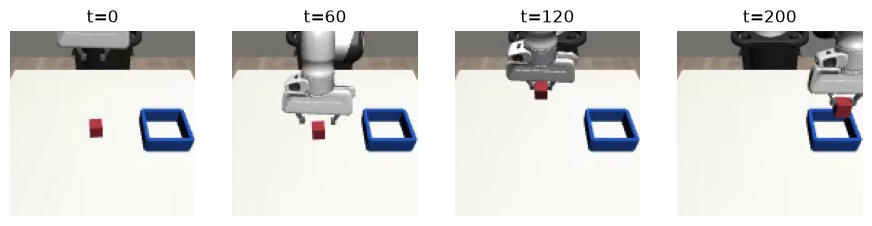

In [8]:
import matplotlib.pyplot as plt

im = ds[rows[60]]["observation.images.top"]  # decodes one video frame
print(im.shape, im.dtype, f"min {im.min():.2f}  max {im.max():.2f}")

fig, ax = plt.subplots(1, 4, figsize=(11, 3))
for a, t in zip(ax, [0, 60, 120, 200]):  # same 4 moments of demo 2 as step 2
    a.imshow(ds[rows[t]]["observation.images.top"].permute(1, 2, 0))  # [3, H, W] -> [H, W, 3]
    a.set_title(f"t={t}")
    a.axis("off")

### step 8 — all top frames into RAM (~10 s)


In [9]:
# decode every top frame once, kept as uint8: 4x smaller than float32, and the training loop
# never touches the video again
top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
for i in range(len(ds)):
    top[i] = (ds[i]["observation.images.top"] * 255).round().to(torch.uint8).numpy()
print(f"{top.shape=}  {top.nbytes / 1e6:.0f} MB")

top.shape=(5288, 3, 128, 128)  260 MB


### step 9 — a conv stack: image in, feature maps out


In [10]:
# Conv2d(in, out, kernel, stride, padding): stride 2 halves H and W
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16]
        nn.ReLU(),
    )


x = torch.tensor(top[:4]).float() / 255  # [B, 3, 128, 128] = [4, 3, 128, 128]
for layer in make_conv():
    x = layer(x)
    if isinstance(layer, nn.Conv2d):
        print(f"Conv2d -> {list(x.shape)}")

Conv2d -> [4, 32, 64, 64]
Conv2d -> [4, 64, 32, 32]
Conv2d -> [4, 128, 16, 16]
Conv2d -> [4, 64, 16, 16]


### step 10 — average each map, join with the state


In [11]:
feat = x.mean(dim=(2, 3))  # [B, 64, 16, 16] -> [B, 64], each map averaged to one number
st = torch.tensor(state[:4])  # [B, 8], the same 4 frames
inp = torch.cat([feat, st], dim=-1)  # [B, 64 + 8] = [4, 72]
print(f"{feat.shape=}  {st.shape=}  {inp.shape=}")

feat.shape=torch.Size([4, 64])  st.shape=torch.Size([4, 8])  inp.shape=torch.Size([4, 72])


### step 11 — one `Net`: image + state in, action out


In [12]:
from torch import Tensor


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = make_conv()  # step 9's stack, fresh weights for every Net()
        self.head = nn.Sequential(nn.Linear(64 + 8, 512), nn.ReLU(), nn.Linear(512, 8))

    def forward(self, im: Tensor, st: Tensor) -> Tensor:
        # im: [B, 3, 128, 128] floats in [0, 1]
        # st: [B, 8]
        # out: [B, 8], one action per frame
        feat = self.conv(im).mean(dim=(2, 3))  # [B, 64, 16, 16] -> [B, 64]
        return self.head(torch.cat([feat, st], dim=-1))  # [B, 72] -> [B, 8]


net = Net()
print("params", sum(p.numel() for p in net.parameters()))
print(net(torch.tensor(top[:4]).float() / 255, torch.tensor(state[:4])).shape)

params 210056
torch.Size([4, 8])


### step 12 — train it on the GPU (~30 s)


In [13]:
dev = "cuda"
IMtr = torch.tensor(top[~is_val]).to(dev)  # [Ntr, 3, H, W] uint8, the whole train set on the GPU
IMva = torch.tensor(top[is_val]).to(dev)  # [Nva, 3, H, W] uint8
Xtr, Ytr, Xva, Yva = Xtr.to(dev), Ytr.to(dev), Xva.to(dev), Yva.to(dev)

torch.manual_seed(0)
net = Net().to(dev)
opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
for step in range(3001):
    i = torch.randint(0, len(Xtr), (64,), device=dev)  # [64], a random batch of train frames
    loss = (net(IMtr[i].float() / 255, Xtr[i]) - Ytr[i]).abs().mean()  # uint8 -> [0, 1] per batch
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 500 == 0:
        with torch.no_grad():  # val 256 frames at a time: all 1070 at once is a lot of GPU memory
            pred = torch.cat(
                [
                    net(IMva[j : j + 256].float() / 255, Xva[j : j + 256])
                    for j in range(0, len(Xva), 256)
                ]
            )  # [Nva, 8]
            err = (pred - Yva).abs().mean(0)  # [8]
        print(
            f"{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}"
        )

    0  train 0.8830  val arm 0.8888  gripper 0.3867
  500  train 0.0502  val arm 0.0219  gripper 0.1563
 1000  train 0.0253  val arm 0.0150  gripper 0.1202
 1500  train 0.0168  val arm 0.0123  gripper 0.0689
 2000  train 0.0135  val arm 0.0095  gripper 0.0548
 2500  train 0.0124  val arm 0.0094  gripper 0.0692
 3000  train 0.0094  val arm 0.0102  gripper 0.0367


### step 13 — what averaging throws away


In [14]:
# two 16x16 feature maps with the same blob in different places, as if
# the cube were top-left in one frame and bottom-right in another
m = torch.zeros(2, 16, 16)  # [2, H, W]
m[0, 3, 2] = 1.0  # blob at row 3, col 2
m[1, 12, 13] = 1.0  # blob at row 12, col 13
print("averages", m.mean(dim=(1, 2)))  # [2], what step 10 hands the head

averages tensor([0.0039, 0.0039])


### step 14 — where is each map bright? softmax, then average position


In [15]:
cell_col = torch.arange(16.0).repeat(16)  # [256], column of each cell (row-major flatten)
cell_row = torch.arange(16.0).repeat_interleave(16)  # [256], row of each cell
for scale in [1.0, 10.0]:
    w = torch.softmax(m.reshape(2, 256) * scale, dim=-1)  # [2, 256], weights over cells, sum to 1
    x, y = w @ cell_col, w @ cell_row  # [2] each, the weighted-average position
    print(f"scale {scale:4}  x {x.numpy().round(2)}  y {y.numpy().round(2)}")

scale  1.0  x [7.46 7.54]  y [7.47 7.53]
scale 10.0  x [ 2.06 12.94]  y [ 3.05 11.95]


### step 15 — `SpatialSoftmax`: 64 maps → 64 (x, y) points


In [16]:
class SpatialSoftmax(nn.Module):
    def __init__(self, h: int, w: int):
        super().__init__()
        # learn log T, not T: any real log_t gives T = exp(log_t) > 0
        self.log_t = nn.Parameter(torch.zeros(()))
        # step 14's grids, but in [-1, 1] instead of 0..15, so (x, y) sit on a small scale
        self.register_buffer("cell_x", torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer("cell_y", torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        x = p @ self.cell_x  # [B, C]
        y = p @ self.cell_y  # [B, C]
        return torch.stack([x, y], dim=-1).reshape(B, 2 * C)  # [B, C, 2] -> [B, 2C]


ss = SpatialSoftmax(16, 16)
print("toy  ", ss(m[None] * 10).detach().numpy().round(2))  # [1, 4]: (x, y) of map 0, then map 1
f = make_conv()(torch.tensor(top[:4]).float() / 255)  # [4, 64, 16, 16]
print("real ", f.shape, "->", ss(f).shape)

toy   [[-0.72 -0.59  0.72  0.59]]
real  torch.Size([4, 64, 16, 16]) -> torch.Size([4, 128])


### step 16 — `SSNet`: step 11's net with spatial softmax in place of the average


In [17]:
class SSNet(nn.Module):
    def __init__(self):
        super().__init__()
        # [:-1] drops the last ReLU: it would zero every negative, flattening the maps
        # the softmax needs to be peaky
        self.conv = make_conv()[:-1]
        self.ss = SpatialSoftmax(16, 16)
        self.head = nn.Sequential(nn.Linear(128 + 8, 512), nn.ReLU(), nn.Linear(512, 8))

    def forward(self, im: Tensor, st: Tensor) -> Tensor:
        # im: [B, 3, 128, 128] floats in [0, 1]
        # st: [B, 8]
        # out: [B, 8], one action per frame
        feat = self.ss(self.conv(im))  # [B, 64, 16, 16] -> [B, 128], an (x, y) per map
        return self.head(torch.cat([feat, st], dim=-1))  # [B, 136] -> [B, 8]


net = SSNet()
print(net.conv[-1])
print("params", sum(p.numel() for p in net.parameters()))
print(net(torch.tensor(top[:4]).float() / 255, torch.tensor(state[:4])).shape)

Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
params 242825
torch.Size([4, 8])


### step 17 — the loop as `train(net)`, then train `SSNet` (~30 s)


In [34]:
def train(
    net: nn.Module,
    cams: list[tuple[Tensor, Tensor]] | None = None,
    steps: int = 3000,
    scale: Tensor | float = 1.0,
    shift: int = 0,
) -> Tensor:
    # step 12's loop as a function, so every variant from here on trains the same way
    # cams: (train frames, val frames) per camera, uint8, in the order net takes them;
    #   default top only (step 24 adds the wrist)
    # scale: [8] or 1, each column's error is divided by it before the mean (step 20)
    # shift: if > 0, every training batch is random_shift-ed by up to this many px (step 31);
    #   val never is
    # out: [8], val error per column at the last step
    cams = cams or [(IMtr, IMva)]
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    for step in range(steps + 1):
        i = torch.randint(0, len(Xtr), (64,), device=dev)  # [64], a random batch of train frames
        ims = [tr[i].float() / 255 for tr, _ in cams]  # per camera [64, 3, H, W]
        if shift:
            ims = [random_shift(im, shift) for im in ims]  # each camera its own shift
        loss = ((net(*ims, Xtr[i]) - Ytr[i]) / scale).abs().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            with torch.no_grad():  # val 256 frames at a time
                pred = torch.cat(
                    [
                        net(*[va[j : j + 256].float() / 255 for _, va in cams], Xva[j : j + 256])
                        for j in range(0, len(Xva), 256)
                    ]
                )  # [Nva, 8]
                err = (pred - Yva).abs().mean(0)  # [8]
            print(f"{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}")
    return err


torch.manual_seed(0)
err = train(SSNet().to(dev))

    0  train 0.9390  val arm 0.9646  gripper 0.3820
  500  train 0.0342  val arm 0.0226  gripper 0.0587
 1000  train 0.0177  val arm 0.0165  gripper 0.0356
 1500  train 0.0153  val arm 0.0205  gripper 0.0386
 2000  train 0.0122  val arm 0.0147  gripper 0.0349
 2500  train 0.0123  val arm 0.0156  gripper 0.0283
 3000  train 0.0124  val arm 0.0119  gripper 0.0235


### step 18 — how big is each column?


In [19]:
# per-column scale, train split only
for name, a in [("state", state[~is_val]), ("action", action[~is_val])]:
    print(f"{name:6s} mean {a.mean(0)}")
    print(f"{name:6s} std  {a.std(0)}")

state  mean [ 0.094  0.545 -0.    -2.226 -0.036  2.861  0.918  0.71 ]
state  std  [0.151 0.194 0.034 0.146 0.058 0.159 0.187 0.189]
action mean [ 0.105  0.562 -0.001 -2.209 -0.039  2.86   0.931  0.36 ]
action std  [0.158 0.191 0.035 0.135 0.06  0.161 0.196 0.48 ]


### step 19 — normalisation stats: state, action, image


In [20]:
# train split only: stats fitted on data that includes val frames would leak val into training
s_mean, s_std = Xtr.mean(0), Xtr.std(0)  # [8] each, on the GPU like Xtr
a_mean, a_std = Ytr.mean(0), Ytr.std(0)  # [8] each

sub = IMtr[::20].float() / 255  # [~211, 3, H, W], every 20th train frame is plenty for pixel stats
i_mean = sub.mean(dim=(0, 2, 3)).reshape(1, 3, 1, 1)  # one per colour channel, shaped to broadcast
i_std = sub.std(dim=(0, 2, 3)).reshape(1, 3, 1, 1)  # over [B, 3, H, W]
print("image mean", i_mean.flatten().cpu().numpy(), " std", i_std.flatten().cpu().numpy())

image mean [0.804 0.799 0.795]  std [0.283 0.279 0.26 ]


### step 20 — normalise both ends (~30 s)


In [21]:
class NormSSNet(SSNet):
    def forward(self, im: Tensor, st: Tensor) -> Tensor:
        # im: [B, 3, 128, 128] floats in [0, 1]
        # st: [B, 8] radians
        # out: [B, 8] radians, so val scoring is unchanged
        im = (im - i_mean) / i_std  # each colour channel to mean 0, std 1
        st = (st - s_mean) / s_std  # each joint to mean 0, std 1
        out = super().forward(im, st)  # [B, 8], the head predicts in std units
        return out * a_std + a_mean  # back to radians


torch.manual_seed(0)
err = train(NormSSNet().to(dev), scale=a_std)  # loss counts std units, not radians

    0  train 0.8096  val arm 0.1129  gripper 0.4464
  500  train 0.0654  val arm 0.0067  gripper 0.0568
 1000  train 0.0494  val arm 0.0058  gripper 0.0374
 1500  train 0.0421  val arm 0.0059  gripper 0.0389
 2000  train 0.0306  val arm 0.0052  gripper 0.0335
 2500  train 0.0295  val arm 0.0051  gripper 0.0325
 3000  train 0.0254  val arm 0.0051  gripper 0.0291


### step 21 — the wrist camera


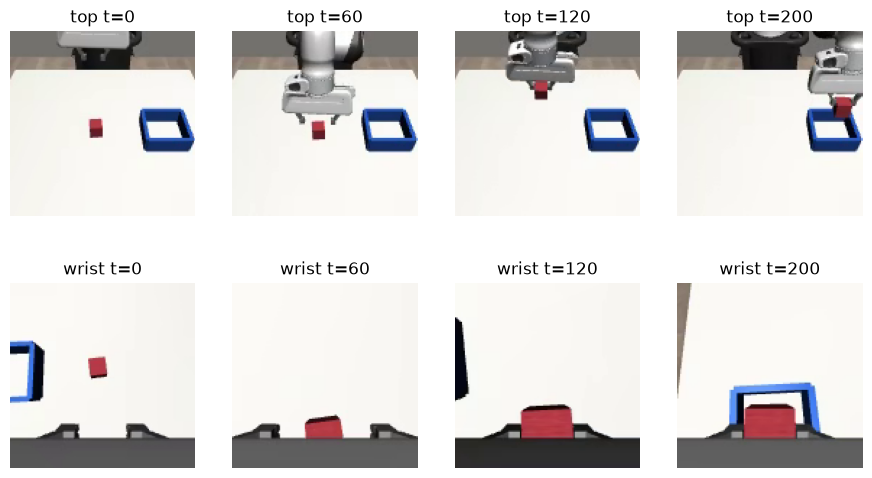

In [22]:
# same as step 8, for the camera on the gripper (~10 s)
wrist = np.zeros_like(top)  # [N, 3, H, W] uint8
for i in range(len(ds)):
    wrist[i] = (ds[i]["observation.images.wrist"] * 255).round().to(torch.uint8).numpy()

fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for col, t in enumerate([0, 60, 120, 200]):  # same 4 moments of demo 2 as step 7
    for row, (name, cam) in enumerate([("top", top), ("wrist", wrist)]):
        ax[row, col].imshow(cam[rows[t]].transpose(1, 2, 0))  # [3, H, W] -> [H, W, 3]
        ax[row, col].set_title(f"{name} t={t}")
        ax[row, col].axis("off")

### step 22 — wrist frames to the GPU, and their own stats

In [23]:
WRtr = torch.tensor(wrist[~is_val]).to(dev)  # [Ntr, 3, H, W] uint8, like IMtr in step 12
WRva = torch.tensor(wrist[is_val]).to(dev)  # [Nva, 3, H, W] uint8

# its own pixel stats, as in step 19: a different view, so different colours
sub = WRtr[::20].float() / 255  # [~211, 3, H, W]
w_mean = sub.mean(dim=(0, 2, 3)).reshape(1, 3, 1, 1)
w_std = sub.std(dim=(0, 2, 3)).reshape(1, 3, 1, 1)
print("top   mean", i_mean.flatten().cpu().numpy(), " std", i_std.flatten().cpu().numpy())
print("wrist mean", w_mean.flatten().cpu().numpy(), " std", w_std.flatten().cpu().numpy())

top   mean [0.804 0.799 0.795]  std [0.283 0.279 0.26 ]
wrist mean [0.802 0.782 0.779]  std [0.304 0.317 0.304]


### step 23 — `TwoCamNet`: an encoder per camera, one head

In [24]:
class TwoCamNet(nn.Module):
    def __init__(self):
        super().__init__()
        # one encoder per camera, not shared: the wrist view moves with the arm,
        # so the same pixel means something different every frame
        self.top = nn.Sequential(make_conv()[:-1], SpatialSoftmax(16, 16))  # -> [B, 128]
        self.wrist = nn.Sequential(make_conv()[:-1], SpatialSoftmax(16, 16))  # -> [B, 128]
        self.head = nn.Sequential(nn.Linear(128 + 128 + 8, 512), nn.ReLU(), nn.Linear(512, 8))

    def forward(self, im: Tensor, wr: Tensor, st: Tensor) -> Tensor:
        # im, wr: [B, 3, 128, 128] top and wrist frames, floats in [0, 1]
        # st: [B, 8] radians
        # out: [B, 8] radians
        f_top = self.top((im - i_mean) / i_std)  # [B, 128]
        f_wr = self.wrist((wr - w_mean) / w_std)  # [B, 128], normalised with its own stats
        st = (st - s_mean) / s_std
        out = self.head(torch.cat([f_top, f_wr, st], dim=-1))  # [B, 264] -> [B, 8] in std units
        return out * a_std + a_mean


net = TwoCamNet().to(dev)
print("params", sum(p.numel() for p in net.parameters()))
print(net(IMtr[:4].float() / 255, WRtr[:4].float() / 255, Xtr[:4]).shape)

params 476938
torch.Size([4, 8])


### step 24 — train with both cameras (~40 s)

In [27]:
torch.manual_seed(0)
net = TwoCamNet().to(dev)  # kept: the rollout below drives this one
err = train(net, cams=[(IMtr, IMva), (WRtr, WRva)], scale=a_std)

    0  train 0.8100  val arm 0.1124  gripper 0.4524
  500  train 0.0695  val arm 0.0073  gripper 0.0273
 1000  train 0.0436  val arm 0.0070  gripper 0.0259
 1500  train 0.0354  val arm 0.0052  gripper 0.0211
 2000  train 0.0262  val arm 0.0052  gripper 0.0203
 2500  train 0.0350  val arm 0.0054  gripper 0.0211
 3000  train 0.0244  val arm 0.0049  gripper 0.0174


### step 25 — the simulator: one observation

In [28]:
import logging
import os

os.environ.setdefault("MUJOCO_GL", "egl")  # render without a window; must be set before mujoco loads

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite  # noqa: E402, F401

logging.disable(logging.NOTSET)
logging.getLogger("robosuite_logs").setLevel(logging.ERROR)  # and its later per-episode warnings

from dream_robot.core.registry import make_env  # noqa: E402

env = make_env("robosuite/pick_place_cube")
obs = env.reset(seed=1000)  # seeds 1000+: cube positions no demo was recorded at
print("state", obs.state.shape, obs.state.dtype)
print("images", {c: (im.shape, im.dtype) for c, im in obs.images.items()})

state (8,) float32
images {'top': ((128, 128, 3), dtype('uint8')), 'wrist': ((128, 128, 3), dtype('uint8'))}


### step 26 — `act(obs)`: one observation in, one action out

In [29]:
def frame(im: np.ndarray) -> Tensor:
    # im: [H, W, 3] uint8, as the sim gives it
    # out: [1, 3, H, W] floats in [0, 1] on the GPU, as the net was trained on
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(dev).float() / 255


@torch.no_grad()
def act(obs) -> np.ndarray:
    # out: [8], one action for the sim
    st = torch.from_numpy(obs.state)[None].to(dev)  # [1, 8]
    a = net(frame(obs.images["top"]), frame(obs.images["wrist"]), st)[0].cpu().numpy()  # [8] radians
    a[7] = np.clip(a[7], 0.0, 1.0)  # the gripper command must stay in [0, 1]
    return a


net.eval()
print("state ", obs.state)
print("action", act(obs))

state  [ 0.022  0.195 -0.028 -2.629 -0.008  2.951  0.772  0.521]
action [ 0.034  0.26  -0.018 -2.562 -0.001  2.982  0.793  1.   ]


### step 27 — one rollout

In [30]:
obs = env.reset(seed=1000)
for step in range(600):  # 600 steps = 20 s at 30 Hz; the demos took ~7 s
    r = env.step(act(obs))  # r: observation, terminated, truncated, success, failure_mode
    obs = r.observation
    if r.terminated or r.truncated:
        break
print(f"seed 1000: {'SUCCESS' if r.success else r.failure_mode}  after {step + 1} steps")

seed 1000: no_grasp  after 600 steps


### step 28 — 20 rollouts: the success rate

In [31]:
from collections import Counter


def rollout(seed: int) -> tuple[bool, str, int]:
    # step 27's loop as a function
    # out: (success, failure mode, steps taken)
    obs = env.reset(seed=seed)
    for step in range(600):
        r = env.step(act(obs))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


results = {seed: rollout(seed) for seed in range(1000, 1020)}  # 20 unseen cube positions
for seed, (ok, mode, steps) in results.items():
    print(seed, "SUCCESS" if ok else mode, steps)
print(f"success {sum(ok for ok, _, _ in results.values())}/20")
print("failures", Counter(mode for ok, mode, _ in results.values() if not ok))

1000 no_grasp 600
1001 no_grasp 600
1002 no_grasp 600
1003 no_grasp 600
1004 no_grasp 600
1005 no_grasp 600
1006 no_grasp 600
1007 no_grasp 600
1008 no_grasp 600
1009 no_grasp 600
1010 no_grasp 600
1011 no_grasp 600
1012 no_grasp 600
1013 no_grasp 600
1014 no_grasp 600
1015 no_grasp 600
1016 no_grasp 600
1017 no_grasp 600
1018 no_grasp 600
1019 no_grasp 600
success 0/20
failures Counter({'no_grasp': 20})


### step 29 — film one failure

In [32]:
from dream_robot.core.video import observation_panel, write_video

obs = env.reset(seed=1000)
frames = []  # each [H, W, 3]: the wide view for us, the policy's two cameras beside it
for step in range(600):
    frames.append(observation_panel(env.render(), obs.images))
    r = env.step(act(obs))
    obs = r.observation
    if r.terminated or r.truncated:
        break
print(write_video(frames, REPO / "scratch/bc2/rollout_seed1000.mp4", fps=env.control_hz))

/home/rahul/Documents/codes/ml/dream-robot/scratch/bc2/rollout_seed1000.mp4


### step 30 — random shift: the same frame, moved a few pixels

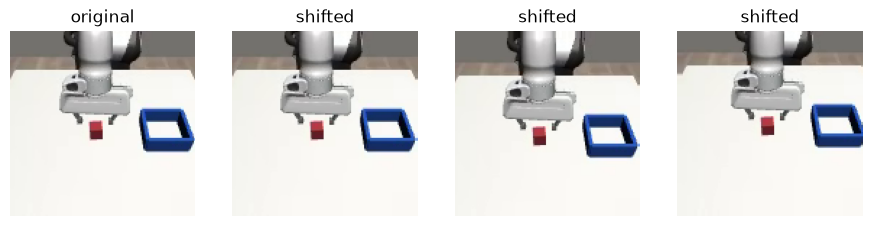

In [33]:
import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode="replicate")  # [B, 3, H + 2p, W + 2p]
    dy, dx = torch.randint(0, 2 * pad + 1, (2,)).tolist()  # where the H x W window starts
    return x[:, :, dy : dy + H, dx : dx + W]


torch.manual_seed(1)
x = torch.tensor(top[rows[60]]).float()[None] / 255  # [1, 3, H, W], demo 2 at t=60
fig, ax = plt.subplots(1, 4, figsize=(11, 3))
ax[0].imshow(x[0].permute(1, 2, 0))
ax[0].set_title("original")
for a in ax[1:]:
    a.imshow(random_shift(x)[0].permute(1, 2, 0))
    a.set_title("shifted")
for a in ax:
    a.axis("off")

### step 31 — train with random shift (~40 s)

In [35]:
torch.manual_seed(0)
net = TwoCamNet().to(dev)
err = train(net, cams=[(IMtr, IMva), (WRtr, WRva)], scale=a_std, shift=4)  # the only change: shift=4

    0  train 0.8100  val arm 0.1124  gripper 0.4524
  500  train 0.0833  val arm 0.0081  gripper 0.0548
 1000  train 0.0666  val arm 0.0073  gripper 0.0367
 1500  train 0.0486  val arm 0.0062  gripper 0.0338
 2000  train 0.0398  val arm 0.0054  gripper 0.0268
 2500  train 0.0417  val arm 0.0051  gripper 0.0304
 3000  train 0.0383  val arm 0.0049  gripper 0.0298


### step 32 — the 20 rollouts again

In [36]:
# same 20 seeds as step 28; act() reads the global net, now the shifted one
results = {seed: rollout(seed) for seed in range(1000, 1020)}
for seed, (ok, mode, steps) in results.items():
    print(seed, "SUCCESS" if ok else mode, steps)
print(f"success {sum(ok for ok, _, _ in results.values())}/20")
print("failures", Counter(mode for ok, mode, _ in results.values() if not ok))

1000 no_grasp 600
1001 no_grasp 600
1002 SUCCESS 225
1003 no_grasp 600
1004 no_grasp 600
1005 no_grasp 600
1006 no_grasp 600
1007 no_grasp 600
1008 no_grasp 600
1009 no_grasp 600
1010 no_grasp 600
1011 no_grasp 600
1012 no_grasp 600
1013 no_grasp 600
1014 no_grasp 600
1015 SUCCESS 197
1016 no_grasp 600
1017 no_grasp 600
1018 no_grasp 600
1019 SUCCESS 246
success 3/20
failures Counter({'no_grasp': 17})


### step 33 — shift vs no shift, 3 training runs each (~10 min)

In [37]:
# 3 training seeds x {no shift, shift 4}, 20 rollouts each (~10 min).
# One run of 20 swings by several successes, so a single pair can't settle steps 28 vs 32
confirm = {}  # (shift, seed) -> successes out of 20
for seed in [0, 1, 2]:
    for shift in [0, 4]:
        torch.manual_seed(seed)
        net = TwoCamNet().to(dev)  # act() and rollout() read this global
        train(net, cams=[(IMtr, IMva), (WRtr, WRva)], scale=a_std, shift=shift)
        net.eval()
        confirm[shift, seed] = sum(rollout(s)[0] for s in range(1000, 1020))
        print(f"=== seed {seed}  shift {shift}: {confirm[shift, seed]}/20")

for shift in [0, 4]:
    runs = [confirm[shift, seed] for seed in [0, 1, 2]]
    print(f"shift {shift}: {runs} -> {sum(runs)}/60")

    0  train 0.8100  val arm 0.1124  gripper 0.4524
  500  train 0.0682  val arm 0.0074  gripper 0.0273
 1000  train 0.0424  val arm 0.0060  gripper 0.0224
 1500  train 0.0342  val arm 0.0054  gripper 0.0224
 2000  train 0.0283  val arm 0.0055  gripper 0.0182
 2500  train 0.0404  val arm 0.0053  gripper 0.0226
 3000  train 0.0257  val arm 0.0052  gripper 0.0218
=== seed 0  shift 0: 1/20
    0  train 0.8100  val arm 0.1124  gripper 0.4524
  500  train 0.0817  val arm 0.0079  gripper 0.0666
 1000  train 0.0602  val arm 0.0068  gripper 0.0323
 1500  train 0.0500  val arm 0.0062  gripper 0.0346
 2000  train 0.0406  val arm 0.0058  gripper 0.0285
 2500  train 0.0416  val arm 0.0053  gripper 0.0256
 3000  train 0.0381  val arm 0.0052  gripper 0.0265
=== seed 0  shift 4: 8/20
    0  train 0.8245  val arm 0.1110  gripper 0.4478
  500  train 0.0527  val arm 0.0079  gripper 0.0239
 1000  train 0.0466  val arm 0.0059  gripper 0.0183
 1500  train 0.0205  val arm 0.0051  gripper 0.0167
 2000  train

### step 34 — wrap-up: what BC buys, where it fails

**The ladder** (val = mean |error| on the 5 held-out demos, radians; single training runs, so ± ~0.003 arm and ± ~0.01 gripper between runs):

| step | policy | val arm | val gripper |
|---|---|---|---|
| 3 | repeat the state | 0.0219 | 0.422 |
| 6 | linear on state | 0.0148 | 0.166 |
| 12 | top camera, conv + average | 0.0102 | 0.037 |
| 17 | + spatial softmax | 0.012–0.017 | 0.021–0.035 |
| 20 | + normalise inputs and targets | 0.0051 | 0.029 |
| 24 | + wrist camera | 0.0049 | 0.017 |
| 31 | + random shift | 0.0049 | 0.030 |

**The rollouts** (20 unseen cube positions per training run, step 33):

| | run 0 | run 1 | run 2 | total |
|---|---|---|---|---|
| two cameras, no shift | 1/20 | 8/20 | 2/20 | 11/60 (18%) |
| two cameras, shift 4 px | 8/20 | 4/20 | 6/20 | 18/60 (30%) |
| expert | | | | 20/20, ~7 s |
| repo ACT, same data | | | | 49/60 (82%) |

**What it buys**

- **Cheap.** 20 demos, ~40 s of training, no reward function, no sim interaction while learning.
- **When it works, it moves like the expert.** Successful rollouts take 197–246 steps (6.6–8.2 s), against the expert's ~210.
- **A working pipeline.** Data → net → `act(obs)` → rollout → success count. Every later policy plugs into the same loop.

**Where it fails**

- **~70–80% of new cube positions.** Every failure looked at (37 across steps 28 and 32) was `no_grasp`: it reaches the cube, ends up beside it, and hovers there for the rest of the 20 s (step 29's video).
- **Validation error doesn't predict success.** Val error falls ~4× from step 12 to step 24 while success stays near zero, and random shift made val gripper *worse* (0.017 → 0.030) while success went up.
- **Training runs disagree.** The same code gives 1–8/20 depending on the seed. One run can't rank two variants; this needed 3 per variant, and even 60 rollouts each leave 18% vs 30% only suggestive.
- **Compounding error.** It only saw states the expert visited. Its own small errors lead to states no demo covers (slightly beside the cube), with no example of how to recover.
- **One frame in, one action out.** No memory of the last few frames and no plan for the next ones; when it's unsure it averages into a hover.

**What would fix each**

- demos that include recovering from mistakes (a noisy expert) → compounding error
- predicting a chunk of future actions and committing to it (ACT) → the hover beside the cube
- a multimodal action head (diffusion / flow matching) → averaging between different valid motions
- detecting failure and retrying → turning 30% per attempt into more successes